# Analyze Saved Benchmark Runs

This notebook loads one saved run from `results/` and creates a compact, student-friendly analysis of the holdout results.

It supports both of these layouts:

1. A flat run directory with one shared summary file and shared `history/` and `models/` folders.
2. A nested run directory like `cpcn-h200`, where each benchmark has its own subdirectory with its own summary, history, and model artifacts.

It focuses on two kinds of figures:

1. For each test function, one `2 x 2` comparison figure with:
   - `MAPE` results
   - runtime results
   - `R^2` results
   - `MAPE` vs `R^2`
2. Learning-behaviour figures based on the saved history files, using only:
   - train mean
   - validation mean
   - a confidence band (`mean +/- 1 std`)

The goal is to make the comparisons easy to read without too much clutter.


## Setup

Set the run name in the next cell. The notebook then reads the saved summary CSV files and history JSON files for that run, whether they are stored in a flat folder or split into benchmark subfolders.


In [1]:
from pathlib import Path
import json
import os
import re
import sys

mpl_config = Path("/tmp/matplotlib")
mpl_config.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(mpl_config))

cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents]
repo_root = next(path for path in candidates if (path / "src" / "qvnn_pc").exists())
sys.path.insert(0, str(repo_root / "src"))

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display


In [2]:
RUN_NAME = "cpcn-h200"
SUMMARY_FILES = ("cpcn_benchmark.csv", "architecture_comparison.csv")
RUN_CONFIG_FILE = "run_config.json"
SHOW_FUNCTIONS = None  # Example: ["ackley", "rastrigin"]
SHOW_MODELS = None     # Example: ["CPCN", "CMLP", "GHR"]
FIG_DPI = 120


In [3]:
def _iter_run_sections(run_dir: Path) -> list[Path]:
    if any((run_dir / filename).exists() for filename in SUMMARY_FILES):
        return [run_dir]

    section_dirs = [
        path
        for path in sorted(run_dir.iterdir())
        if path.is_dir()
        and (
            any((path / filename).exists() for filename in SUMMARY_FILES)
            or (path / RUN_CONFIG_FILE).exists()
            or (path / "history").exists()
            or (path / "models").exists()
        )
    ]
    return section_dirs or [run_dir]


def _load_summary_frame(section_dir: Path) -> pd.DataFrame | None:
    for filename in SUMMARY_FILES:
        summary_path = section_dir / filename
        if summary_path.exists():
            summary_df = pd.read_csv(summary_path)
            summary_df["source_run"] = section_dir.name
            return summary_df
    return None


def _load_run_summary(run_dir: Path) -> tuple[pd.DataFrame, list[Path]]:
    section_dirs = _iter_run_sections(run_dir)
    frames: list[pd.DataFrame] = []
    skipped_sections: list[Path] = []

    for section_dir in section_dirs:
        section_summary = _load_summary_frame(section_dir)
        if section_summary is None:
            skipped_sections.append(section_dir)
            continue

        frames.append(section_summary)

    if not frames:
        # Return an empty summary DataFrame instead of raising so the notebook
        # can continue and build plots from available history files.
        cols = [
            "test_function",
            "algorithm",
            "repetition",
            "test_mape",
            "test_r2",
            "runtime_seconds",
            "source_run",
        ]
        summary_df = pd.DataFrame(columns=cols)
    else:
        summary_df = pd.concat(frames, ignore_index=True)

    if "algorithm" in summary_df.columns:
        summary_df["algorithm"] = summary_df["algorithm"].astype(str).str.upper()

    return summary_df, skipped_sections


def _extract_history_series(payload: dict, candidate_keys: list[str]) -> list[float]:
    for key in candidate_keys:
        if key in payload:
            return payload[key]
    raise KeyError(f"None of the expected history keys were found: {candidate_keys}")


In [4]:
cwd = Path.cwd().resolve()
# locate repository root (assumes src/qvnn_pc exists in repo)
candidates = [cwd, *cwd.parents]
repo_root = next(path for path in candidates if (path / "src" / "qvnn_pc").exists())

results_root = repo_root / "results"
available_runs = sorted(path.name for path in results_root.iterdir() if path.is_dir())
run_dir = results_root / RUN_NAME

if not run_dir.exists():
    raise FileNotFoundError(f"Run directory not found: {run_dir}")

# Try to load summary files if present, but don't fail the notebook if missing.
try:
    summary_df, skipped_sections = _load_run_summary(run_dir)
except Exception:
    summary_df = pd.DataFrame()
    skipped_sections = []

print(f"Selected run: {run_dir}")
print(f"Loaded summary rows: {len(summary_df)}")


Selected run: /home/lukas/src/Sem4/OML/oml_fs2026/PCQVNN/results/cpcn-h200
Loaded summary rows: 40


In [5]:
if SHOW_FUNCTIONS is not None and not summary_df.empty:
    summary_df = summary_df[summary_df["test_function"].isin(SHOW_FUNCTIONS)].copy()
if SHOW_MODELS is not None and not summary_df.empty:
    summary_df = summary_df[summary_df["algorithm"].isin(SHOW_MODELS)].copy()

if summary_df.empty:
    print("No summary CSVs found (or filters removed all rows); continuing using history files for learning plots.")
    # Initialize empty orders; they will be derived from history files later if available.
    function_order = []
    model_order = []
else:
    preferred_function_order = ["ackley", "griewank", "rastrigin", "schwefel"]
    function_order = [name for name in preferred_function_order if name in set(summary_df["test_function"])]
    function_order += [name for name in sorted(summary_df["test_function"].unique()) if name not in function_order]

    preferred_model_order = ["CPCN", "CMLP", "GHR", "Arena", "Nitta"]
    model_order = [name for name in preferred_model_order if name in set(summary_df["algorithm"])]
    model_order += [name for name in sorted(summary_df["algorithm"].unique()) if name not in model_order]

    summary_df["test_function"] = pd.Categorical(summary_df["test_function"], categories=function_order, ordered=True)
    summary_df["algorithm"] = pd.Categorical(summary_df["algorithm"], categories=model_order, ordered=True)
    summary_df = summary_df.sort_values(["test_function", "algorithm", "repetition"]).reset_index(drop=True)

summary_df


,repetition,algorithm,test_function,sample_seed,split_seed,model_seed,shuffle_seed,activation,optimizer,layer_sizes,...,test_r2,test_normalized_mse,test_normalized_mae,test_quaternion_mae,test_free_energy,status,epochs,runtime_seconds,evals,source_run
0,1,CPCN,ackley,0,0,1000000,2000000,tanh,SGD,1-5-5-5-1,...,-1.498461e-04,1.026677,0.663936,0.663969,0.163052,completed,300,718.046040,61,ackley
1,2,CPCN,ackley,1,1,1000001,2000001,tanh,SGD,1-5-5-5-1,...,-4.494190e-05,0.951666,0.657366,0.657379,0.159247,completed,300,717.348904,61,ackley
2,3,CPCN,ackley,2,2,1000002,2000002,tanh,SGD,1-5-5-5-1,...,-3.100634e-04,1.070730,0.658985,0.659757,0.165982,completed,300,717.554227,61,ackley
3,4,CPCN,ackley,3,3,1000003,2000003,tanh,SGD,1-5-5-5-1,...,-7.489920e-04,1.083387,0.673119,0.673306,0.173564,completed,300,716.544473,61,ackley
4,5,CPCN,ackley,4,4,1000004,2000004,tanh,SGD,1-5-5-5-1,...,2.002716e-05,0.983974,0.655079,0.655195,0.151036,completed,300,716.290978,61,ackley
5,6,CPCN,ackley,5,5,1000005,2000005,tanh,SGD,1-5-5-5-1,...,-9.326935e-04,0.946431,0.643800,0.644718,0.152749,completed,300,717.312784,61,ackley
6,7,CPCN,ackley,6,6,1000006,2000006,tanh,SGD,1-5-5-5-1,...,-1.206398e-03,0.935261,0.649640,0.651321,0.152008,completed,300,719.315049,61,ackley
7,8,CPCN,ackley,7,7,1000007,2000007,tanh,SGD,1-5-5-5-1,...,-1.233816e-04,0.929088,0.648335,0.648411,0.185414,completed,300,721.462927,61,ackley
8,9,CPCN,ackley,8,8,1000008,2000008,tanh,SGD,1-5-5-5-1,...,-3.933907e-06,0.952518,0.644226,0.644232,0.148479,completed,300,718.220732,61,ackley
9,10,CPCN,ackley,9,9,1000009,2000009,tanh,SGD,1-5-5-5-1,...,-1.197934e-03,0.827895,0.624165,0.624378,0.186186,completed,300,718.504624,61,ackley


## Summary Tables

`MAPE` and `R^2` come from the holdout test set. Runtime is the training runtime saved for each run.

The first table is a tidy summary per function and model. The second table is a pivoted version for quicker side-by-side comparison.


In [6]:
def _format_mean_std(mean_value: float, std_value: float, digits: int = 4) -> str:
    if pd.isna(std_value):
        std_value = 0.0
    return f"{mean_value:.{digits}f} +/- {std_value:.{digits}f}"

if summary_df.empty:
    display(Markdown("**No summary CSV available — skipping holdout comparison tables.**"))
else:
    summary_stats = (
        summary_df.groupby(["test_function", "algorithm"], observed=True)
        .agg(
            runs=("repetition", "count"),
            mape_mean=("test_mape", "mean"),
            mape_std=("test_mape", "std"),
            r2_mean=("test_r2", "mean"),
            r2_std=("test_r2", "std"),
            runtime_mean=("runtime_seconds", "mean"),
            runtime_std=("runtime_seconds", "std"),
        )
        .reset_index()
    )

    summary_stats["MAPE"] = summary_stats.apply(lambda row: _format_mean_std(row.mape_mean, row.mape_std), axis=1)
    summary_stats["R^2"] = summary_stats.apply(lambda row: _format_mean_std(row.r2_mean, row.r2_std), axis=1)
    summary_stats["Runtime (s)"] = summary_stats.apply(lambda row: _format_mean_std(row.runtime_mean, row.runtime_std, digits=2), axis=1)

    tidy_table = summary_stats[["test_function", "algorithm", "runs", "MAPE", "R^2", "Runtime (s)"]]
    display(tidy_table)

    pivot_table = (
        summary_stats.set_index(["test_function", "algorithm"])[["MAPE", "R^2", "Runtime (s)"]]
        .unstack("algorithm")
    )
    display(pivot_table)


,test_function,algorithm,runs,MAPE,R^2,Runtime (s)
0,ackley,CPCN,10,0.0387 +/- 0.0008,-0.0005 +/- 0.0005,718.06 +/- 1.50
1,griewank,CPCN,10,0.6184 +/- 0.0213,-0.0005 +/- 0.0007,729.18 +/- 4.43
2,rastrigin,CPCN,10,0.2631 +/- 0.0049,-0.0006 +/- 0.0009,725.92 +/- 4.48
3,schwefel,CPCN,10,0.2104 +/- 0.0027,-0.0000 +/- 0.0014,717.24 +/- 3.76


,MAPE,R^2,Runtime (s)
algorithm,CPCN,CPCN,CPCN
test_function,,,
ackley,0.0387 +/- 0.0008,-0.0005 +/- 0.0005,718.06 +/- 1.50
griewank,0.6184 +/- 0.0213,-0.0005 +/- 0.0007,729.18 +/- 4.43
rastrigin,0.2631 +/- 0.0049,-0.0006 +/- 0.0009,725.92 +/- 4.48
schwefel,0.2104 +/- 0.0027,-0.0000 +/- 0.0014,717.24 +/- 3.76


## Plot Helpers

The next helpers keep the figures visually consistent and easy to read. Every model gets the same color in every plot.


In [7]:
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.dpi"] = FIG_DPI

palette = plt.get_cmap("tab10")


def _present_models(df: pd.DataFrame) -> list[str]:
    return [model for model in model_order if model in set(df["algorithm"])]


def _boxplot_with_points(ax, df: pd.DataFrame, metric_col: str, ylabel: str, title: str):
    present_models = _present_models(df)
    values = [df.loc[df["algorithm"] == model, metric_col].to_numpy() for model in present_models]
    positions = np.arange(1, len(present_models) + 1)

    # compute colors for present models
    model_colors = {model: palette(i) for i, model in enumerate(present_models)}

    box = ax.boxplot(values, positions=positions, widths=0.6, patch_artist=True, tick_labels=present_models)
    for patch, model in zip(box["boxes"], present_models):
        patch.set_facecolor(model_colors[model])
        patch.set_alpha(0.45)
    for median in box["medians"]:
        median.set_color("black")
        median.set_linewidth(1.6)

    for xpos, model, series in zip(positions, present_models, values):
        if len(series) == 0:
            continue
        offsets = np.linspace(-0.07, 0.07, num=len(series)) if len(series) > 1 else np.array([0.0])
        ax.scatter(
            np.full(len(series), xpos) + offsets,
            series,
            color=model_colors[model],
            edgecolor="black",
            linewidth=0.5,
            s=34,
            zorder=3,
        )

    ax.set_title(title)
    ax.set_xlabel("Model")
    ax.set_ylabel(ylabel)


def plot_function_comparison(function_name: str, df: pd.DataFrame):
    function_df = df[df["test_function"] == function_name].copy()
    present_models = _present_models(function_df)
    fig, axes = plt.subplots(2, 2, figsize=(13, 9), squeeze=False)
    axes = axes.ravel()

    _boxplot_with_points(
        axes[0],
        function_df,
        metric_col="test_mape",
        ylabel="MAPE",
        title=f"{function_name.capitalize()} MAPE Results (lower is better)",
    )
    _boxplot_with_points(
        axes[1],
        function_df,
        metric_col="runtime_seconds",
        ylabel="Runtime (seconds)",
        title=f"{function_name.capitalize()} Runtime Results (lower is better)",
    )
    _boxplot_with_points(
        axes[2],
        function_df,
        metric_col="test_r2",
        ylabel="R^2",
        title=f"{function_name.capitalize()} R^2 Results (higher is better)",
    )

    # compute colors for present models
    model_colors = {model: palette(i) for i, model in enumerate(present_models)}
    for model in present_models:
        model_df = function_df[function_df["algorithm"] == model]
        axes[3].scatter(
            model_df["test_mape"],
            model_df["test_r2"],
            color=model_colors[model],
            s=60,
            alpha=0.9,
            edgecolor="black",
            linewidth=0.5,
            label=model,
        )
    axes[3].set_title(f"{function_name.capitalize()} MAPE vs R^2")
    axes[3].set_xlabel("MAPE")
    axes[3].set_ylabel("R^2")
    axes[3].legend(title="Model")

    fig.suptitle(f"Holdout Comparison for {function_name.capitalize()}", fontsize=15, y=1.02)
    fig.tight_layout()
    return fig


## Plot Type 1: Holdout Comparison per Function

Read each figure like this:

- the first three panels compare the holdout distributions across models
- the last panel shows the trade-off between `MAPE` and `R^2`
- better models are usually toward **low MAPE**, **low runtime**, and **high `R^2`**


### Ackley

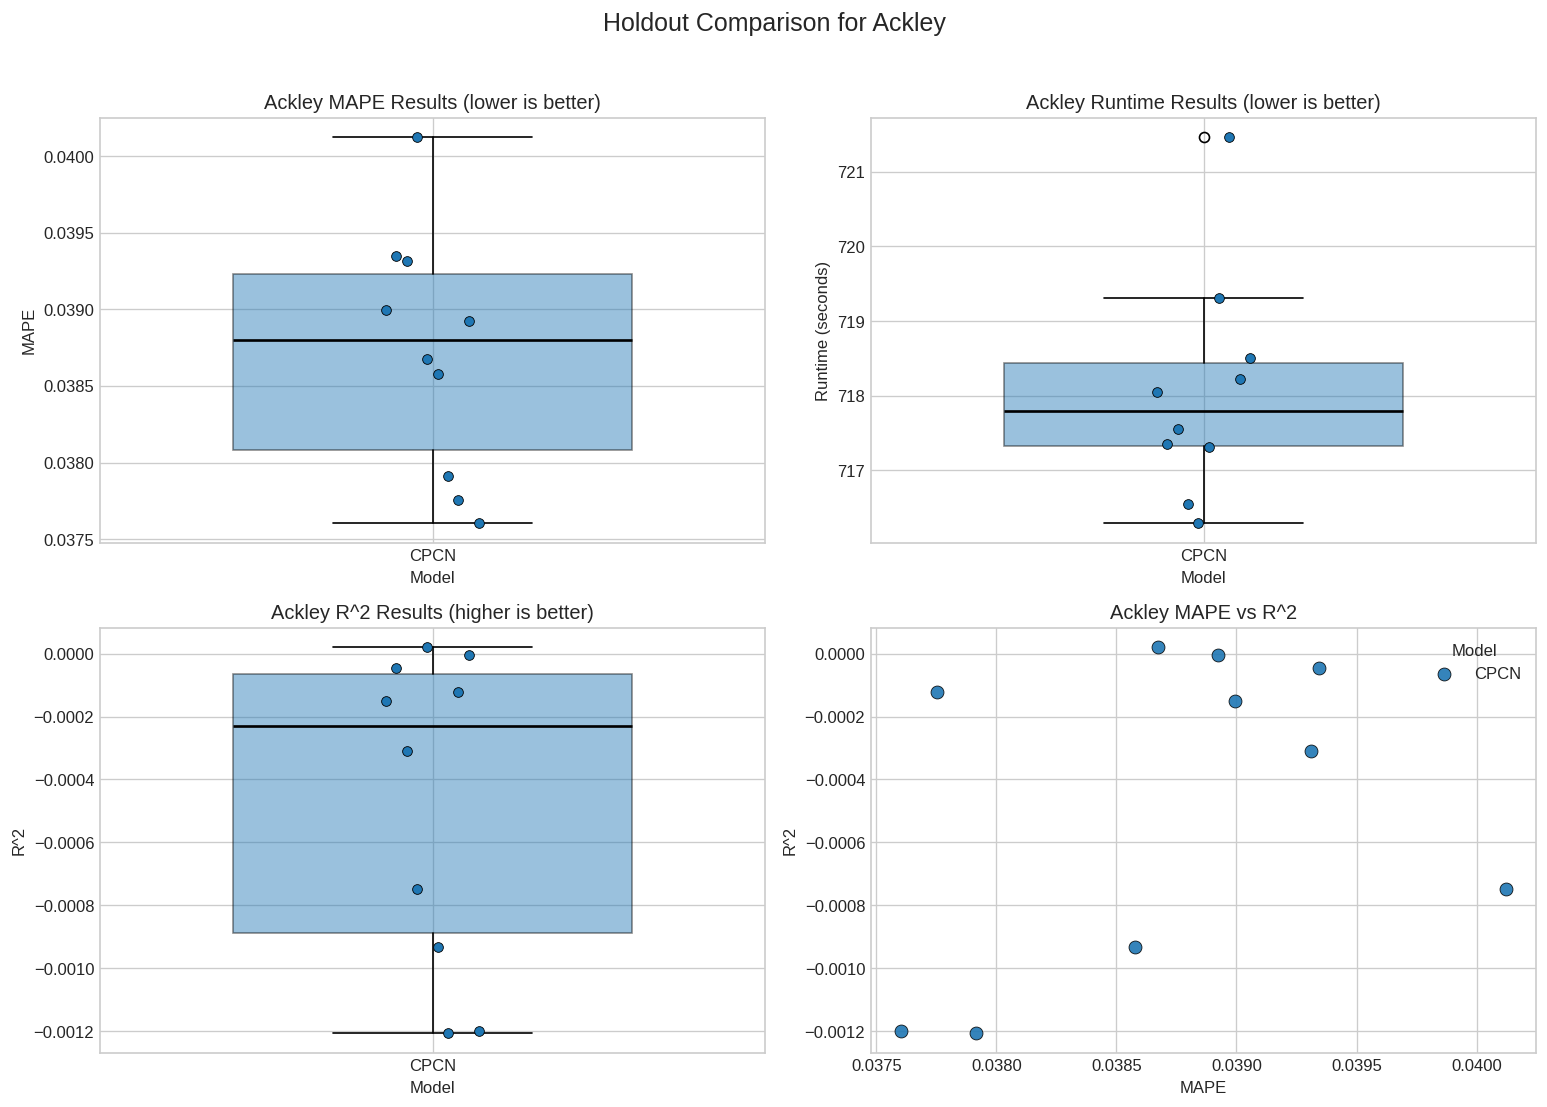

### Griewank

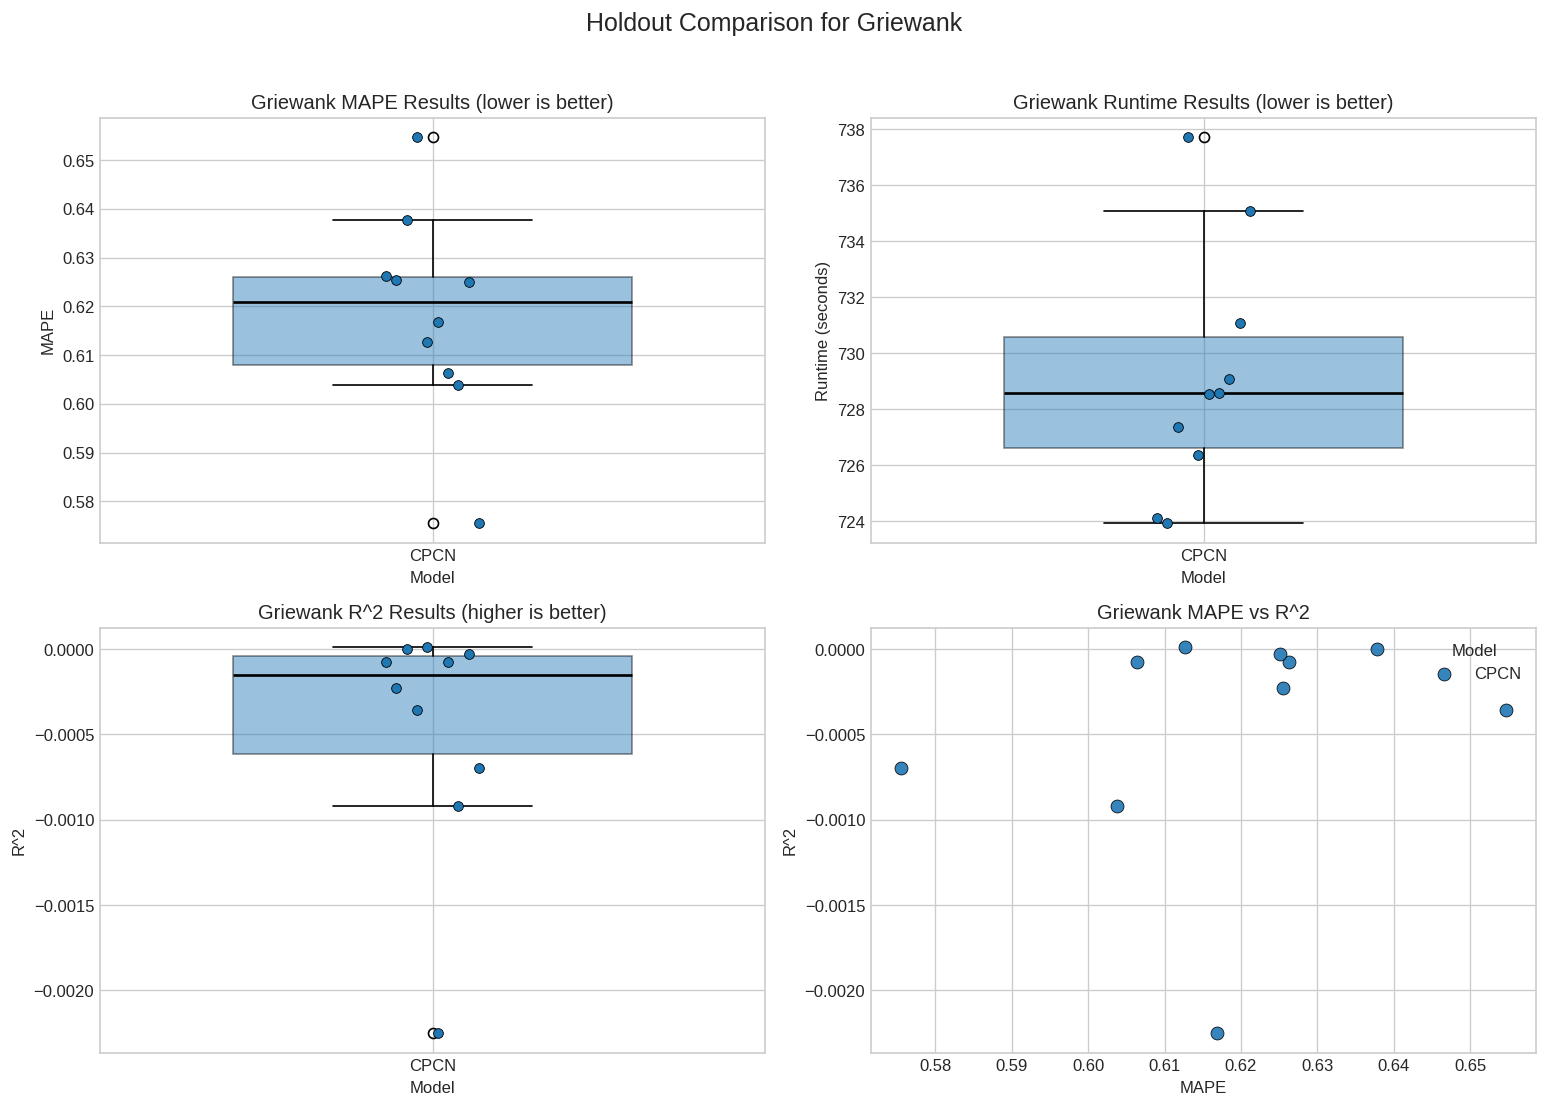

### Rastrigin

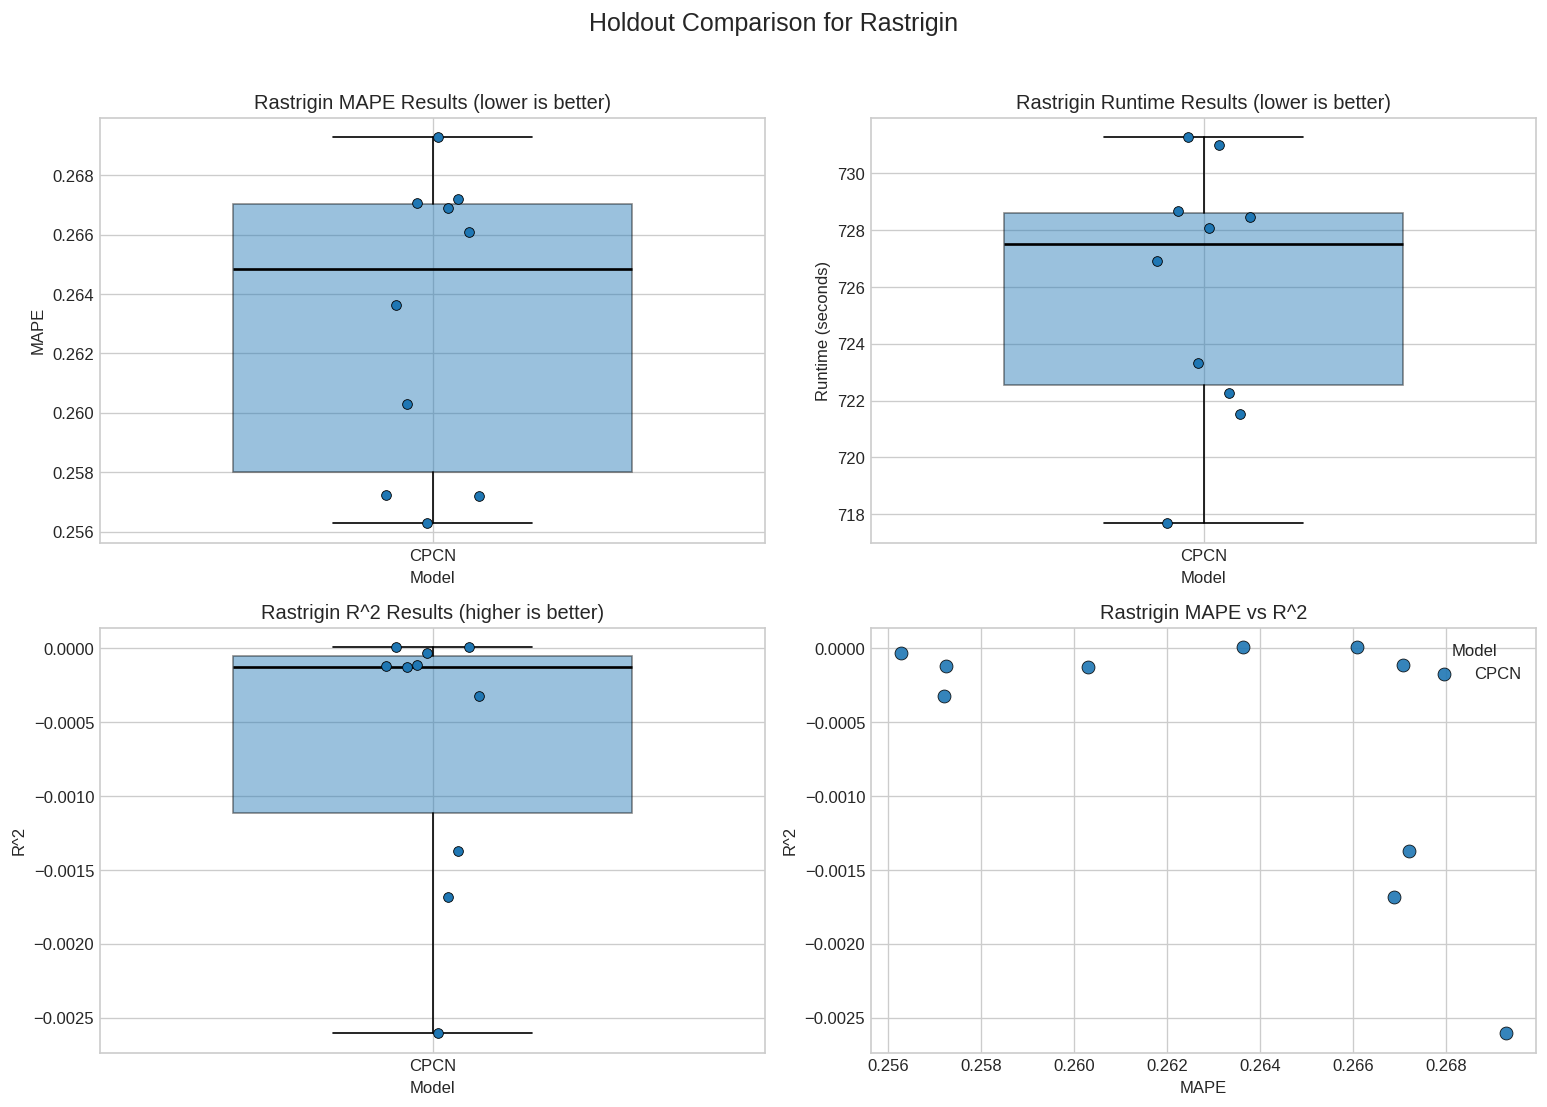

### Schwefel

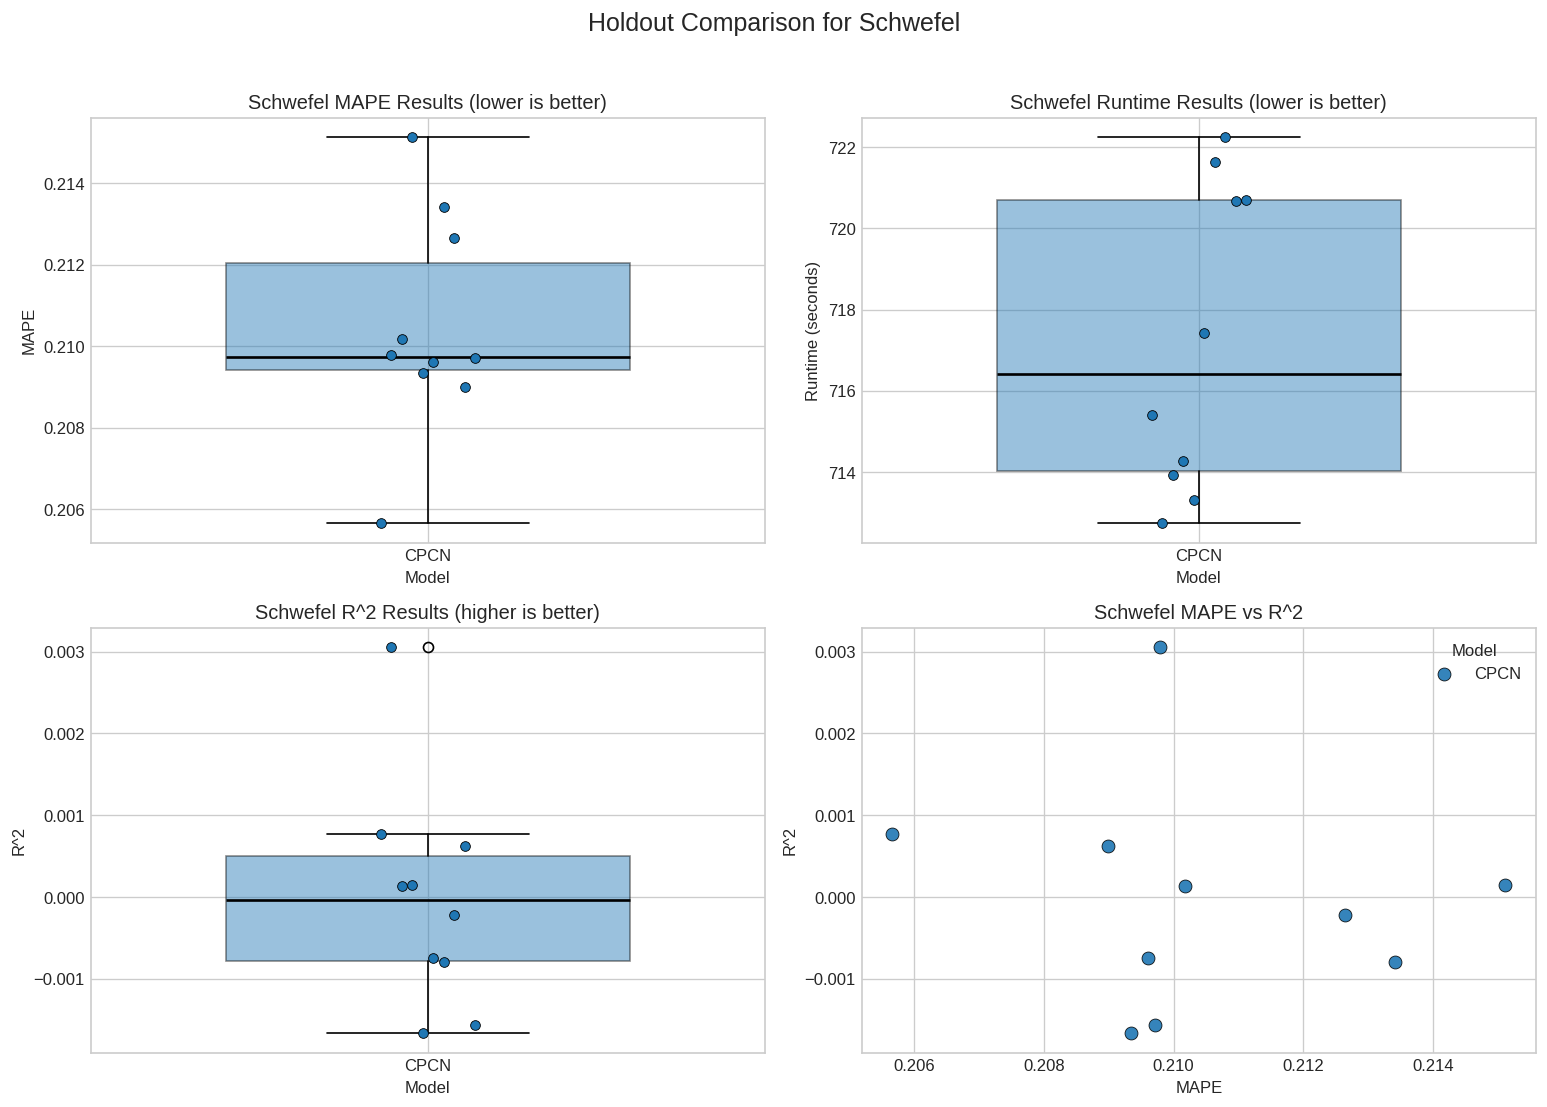

In [8]:
if summary_df.empty:
    display(Markdown("**No summary CSV available — skipping holdout comparison figures.**"))
else:
    for function_name in function_order:
        display(Markdown(f"### {function_name.capitalize()}"))
        plot_function_comparison(function_name, summary_df)
        plt.show()


## Learning Behaviour Data

The saved history files contain per-epoch:

- training MAE
- validation MAE
- training MAPE
- training `R^2`

For clean learning plots, we will only use training and validation MAE and aggregate them across repetitions.


In [9]:
history_pattern = re.compile(r"(?P<function>.+)_(?P<algorithm>[^_]+)_rep(?P<rep>\d+)\.json")

history_rows = []
for section_dir in _iter_run_sections(run_dir):
    history_dir = section_dir / "history"
    if not history_dir.exists():
        continue

    for history_path in sorted(history_dir.glob("*.json")):
        match = history_pattern.fullmatch(history_path.name)
        if match is None:
            continue
        function_name = match.group("function")
        algorithm_name = match.group("algorithm").upper()
        repetition = int(match.group("rep"))
        payload = json.loads(history_path.read_text())
        train_values = _extract_history_series(payload, ["quaternion_mae", "train_quaternion_mae", "train_mae"])
        validation_values = _extract_history_series(payload, [
            "validation_quaternion_mae",
            "val_quaternion_mae",
            "validation_mae",
            "val_mae",
        ])
        curve_length = min(len(train_values), len(validation_values))

        for epoch_idx in range(curve_length):
            history_rows.append(
                {
                    "test_function": function_name,
                    "algorithm": algorithm_name,
                    "repetition": repetition,
                    "epoch": epoch_idx + 1,
                    "train_mae": train_values[epoch_idx],
                    "validation_mae": validation_values[epoch_idx],
                }
            )

history_df = pd.DataFrame(history_rows)

history_df = pd.DataFrame(history_rows)

if not history_df.empty:
    # If we don't have a summary, derive function/model ordering from history files.
    if not function_order:
        preferred_function_order = ["ackley", "griewank", "rastrigin", "schwefel"]
        function_order = [name for name in preferred_function_order if name in set(history_df["test_function"])]
        function_order += [name for name in sorted(history_df["test_function"].unique()) if name not in function_order]
    if not model_order:
        preferred_model_order = ["CPCN", "CMLP", "GHR", "Arena", "Nitta"]
        model_order = [name for name in preferred_model_order if name in set(history_df["algorithm"])]
        model_order += [name for name in sorted(history_df["algorithm"].unique()) if name not in model_order]

    history_df["test_function"] = pd.Categorical(history_df["test_function"], categories=function_order, ordered=True)
    history_df["algorithm"] = pd.Categorical(history_df["algorithm"], categories=model_order, ordered=True)
    history_df = history_df.sort_values(["test_function", "algorithm", "repetition", "epoch"]).reset_index(drop=True)

history_df.head()


,test_function,algorithm,repetition,epoch,train_mae,validation_mae
0,ackley,CPCN,1,1,0.658445,0.668884
1,ackley,CPCN,1,2,0.658417,0.668855
2,ackley,CPCN,1,3,0.658418,0.668856
3,ackley,CPCN,1,4,0.658421,0.668859
4,ackley,CPCN,1,5,0.658425,0.668863


In [ ]:
def plot_learning_behaviour_for_function(function_name: str, history_df: pd.DataFrame):
    function_df = history_df[history_df["test_function"] == function_name].copy()
    present_models = _present_models(function_df)

    fig, axes = plt.subplots(1, len(present_models), figsize=(6.2 * len(present_models), 4.6), squeeze=False)
    axes = axes.ravel()

    for ax, model_name in zip(axes, present_models):
        subset = function_df[function_df["algorithm"] == model_name]
        sns.lineplot(
            data=subset, 
            x="epoch", 
            y="train_mae", 
            estimator="mean", 
            errorbar="se", 
            ax=ax, 
            color="tab:blue", 
            label="Train mean"
        )
        sns.lineplot(
            data=subset, 
            x="epoch", 
            y="validation_mae", 
            estimator="mean", 
            errorbar="se", 
            ax=ax, 
            color="tab:orange", 
            linestyle="--", 
            label="Validation mean"
        )
        ax.set_title(f"{function_name.capitalize()} - {model_name}")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("MAE")

    legend_handles = [
        Line2D([0], [0], color="tab:blue", linewidth=2.2, label="Train mean"),
        Line2D([0], [0], color="tab:orange", linewidth=2.2, linestyle="--", label="Validation mean"),
    ]
    fig.legend(handles=legend_handles, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.04))
    fig.suptitle(f"Learning Behaviour for {function_name.capitalize()}", fontsize=15, y=1.08)
    fig.tight_layout()
    return fig


## Plot Type 2: Learning Behaviour

These plots are intentionally less cluttered than before:

- no single-run lines
- solid blue line = train mean
- dashed orange line = validation mean
- shaded band = `mean +/- 1 std` across repetitions

This makes it much easier to see the general trend of each model.


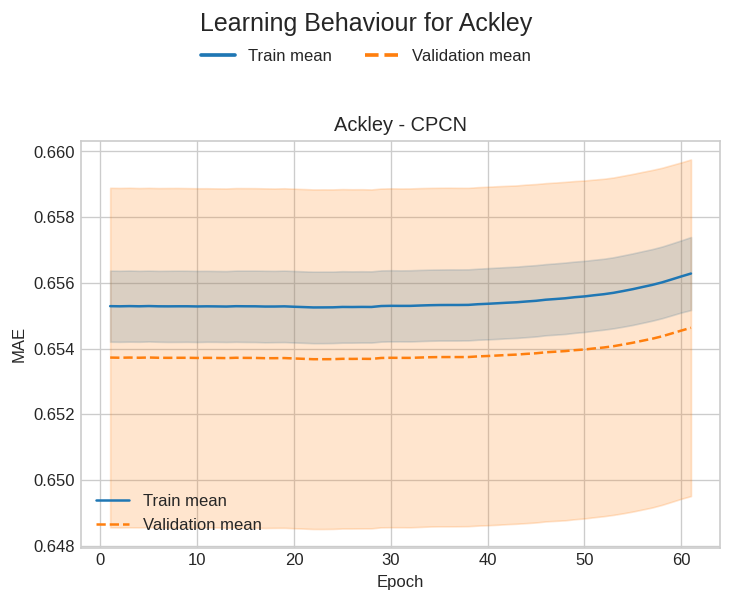

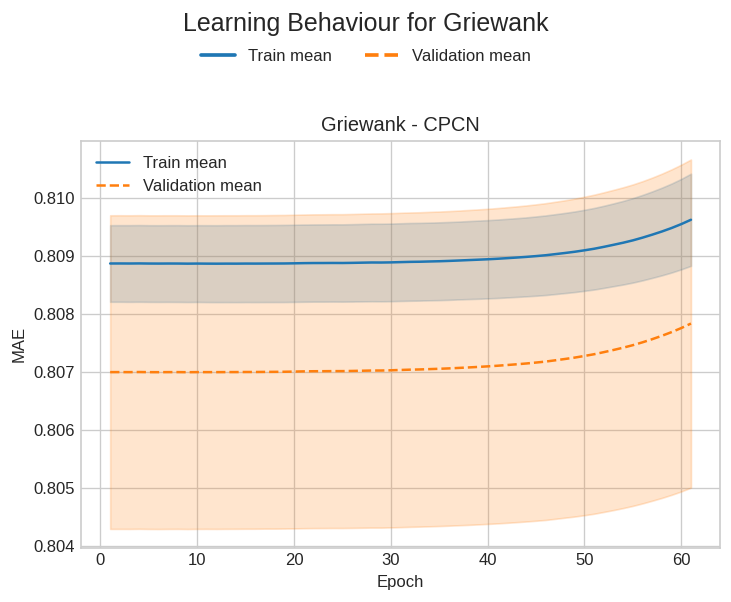

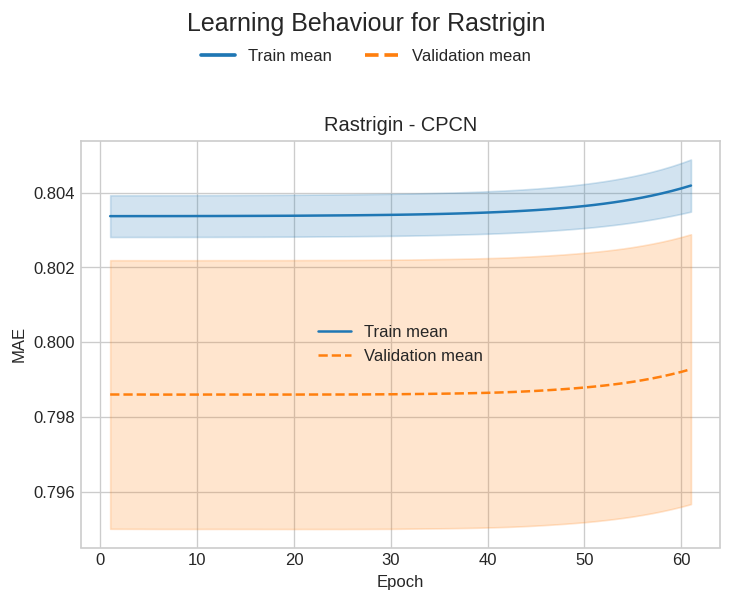

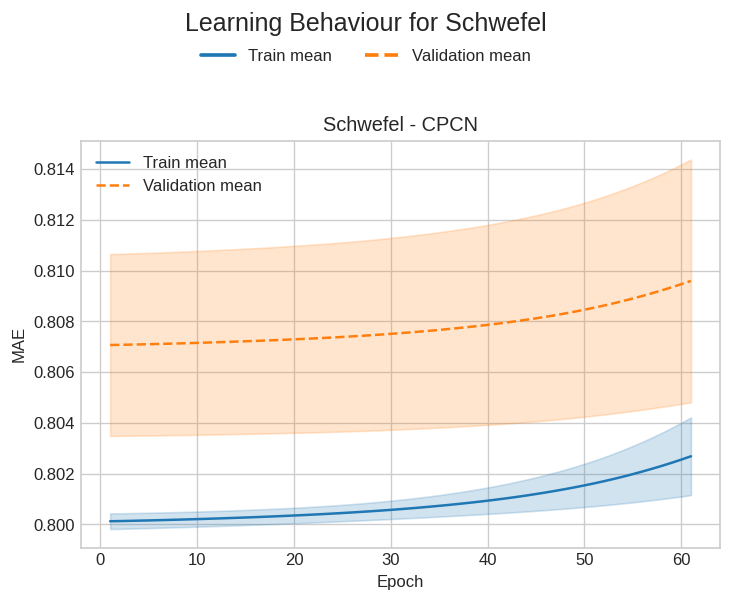

In [12]:
for function_name in function_order:
    plot_learning_behaviour_for_function(function_name, history_df)
    plt.show()
